In [23]:
options(repr.plot.width = 8, repr.plot.height = 5)

In [32]:
sample( c( "A", "B", "C" ), size = 4, replace = TRUE )
rep( 1/6, 6 )

[1] "B" "A" "A" "A"

[1] 0.1666667 0.1666667 0.1666667 0.1666667 0.1666667 0.1666667

In [34]:
simulate_two_dice <- function( n, probabilities = rep( 1/6, 6 ) ) {
    die1 = sample( 1:6, size = n, replace = TRUE, prob = probabilities )
    die2 = sample( 1:6, size = n, replace = TRUE, prob = probabilities )
    return( die1 + die2 )
}

simulate_two_dice( n = 100, probabilities = c( 0, 0.2, 0.2, 0.2, 0.2, 0.2 ))

[1] 12 11  7  9  8 10 11  6 10 11  8  9  6  9  6  7  7  6  7  7 10  9  8  5  7
 [26]  4  9  8  9  7 11  9  9  6  6  5  6 10  6  7  8  8  7 12  8  8 10  9  8 10
 [51] 12 10  8 10  8  9  6  9  9  7  7  8  5  7  9  9  8  9  8  9  9 11 10  7 11
 [76]  8  5 10 10 11 10  6  7  5  4  9  8 12 10  5  8  8  9  6 10  9  7  9 12  8

 [1]  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5


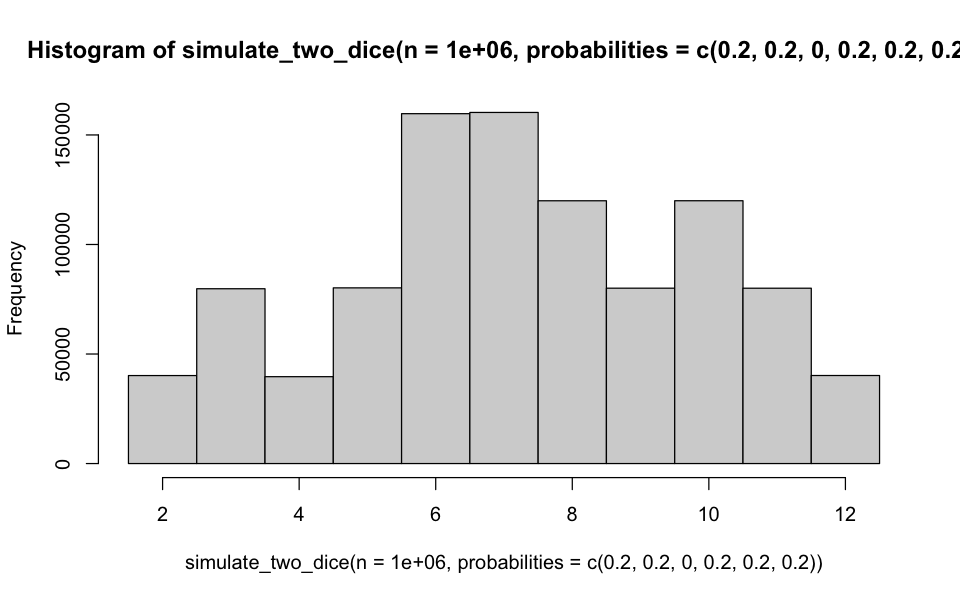

In [39]:
mybreaks = (2:13)-0.5
print( mybreaks )
hist(
    simulate_two_dice( n = 1000000, probabilities = c( 0.2, 0.2, 0, 0.2, 0.2, 0.2 )),
    breaks = mybreaks
)

In [42]:
library( tidyverse )

data = readr::read_tsv( "dice_data1.tsv" )
print(data)

Rows: 30 Columns: 2
── Column specification ─────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
dbl (2): roll, sum_of_dice

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 30 × 2
    roll sum_of_dice
   <dbl>       <dbl>
 1     1           8
 2     2           6
 3     3           8
 4     4           5
 5     5           8
 6     6          11
 7     7          11
 8     8          11
 9     9           6
10    10           8
# ℹ 20 more rows


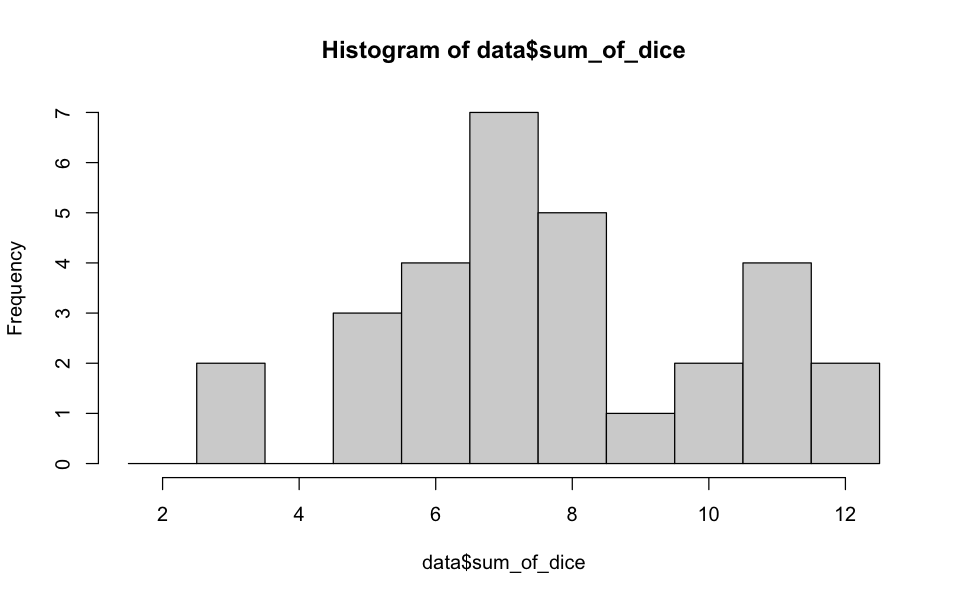

In [43]:
hist( data$sum_of_dice, breaks = mybreaks )

In [60]:
likelihood <- function( observed, probabilities = rep( 1/6, 6 ) ) {
    dice1 = tibble::tibble( dice1 = 1:6, dice1_probability = probabilities )
    dice2 = tibble::tibble( dice2 = 1:6, dice2_probability = probabilities )
    both_dice = (
        dice1
        %>% cross_join( dice2 )
        %>% mutate(
            sum_of_dice = dice1 + dice2,
            probability = dice1_probability * dice2_probability
        )
    )
    probabilities = (
        both_dice
        %>% group_by( sum_of_dice )
        %>% summarise(
            number_of_ways = n(),
            probability = sum( probability )
        )
    )

    result = (
        tibble::tibble( sum_of_dice = observed )
        %>% left_join( probabilities, by = "sum_of_dice" )
    )

    return( result )
}

total_likelihood = function( observed, probabilities = rep( 1/6, 6 ) ) {
    prod( likelihood( observed, probabilities )$probability )
}

# or total_loglikelihood
total_loglikelihood = function( observed, probabilities = rep( 1/6, 6 ) ) {
    sum(
        log(
            likelihood( observed, probabilities )$probability
        )
    )
}

sum_of_dice,number_of_ways,probability
<dbl>,<int>,<dbl>
2,1,0.02777778


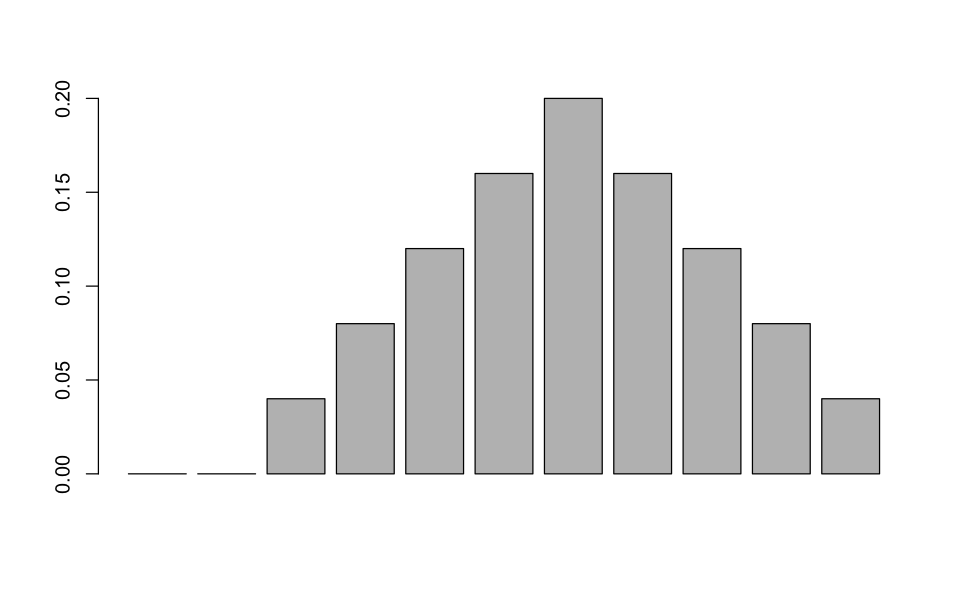

In [54]:
likelihood( 2, probabilities = rep( 1/6, 6 ) )

barplot( likelihood( 2:12, probabilities = c( 0, 0.2, 0.2, 0.2, 0.2, 0.2 ))$probability )

In [62]:
data_likelihoods = likelihood( data$sum_of_dice, probabilities = rep( 1/6, 6 ))
head( data_likelihoods )
total_likelihood( data$sum_of_dice )
total_loglikelihood( data$sum_of_dice )

sum_of_dice,number_of_ways,probability
<dbl>,<int>,<dbl>
8,5,0.13888889
6,5,0.13888889
8,5,0.13888889
5,4,0.11111111
8,5,0.13888889
11,2,0.05555556


[1] 1.649591e-30

[1] -68.57703

In [63]:
exp( -68.5770255520046)
log( 1.64959076809924e-30)

[1] 1.649591e-30

[1] -68.57703

# A tibble: 7 × 2
  model       loglikelihood
  <chr>               <dbl>
1 Normal dice         -68.6
2 Omit 1             -Inf  
3 Omit 2             -Inf  
4 Omit 3              -66.7
5 Omit 4              -68.6
6 Omit 5             -Inf  
7 Omit 6             -Inf  


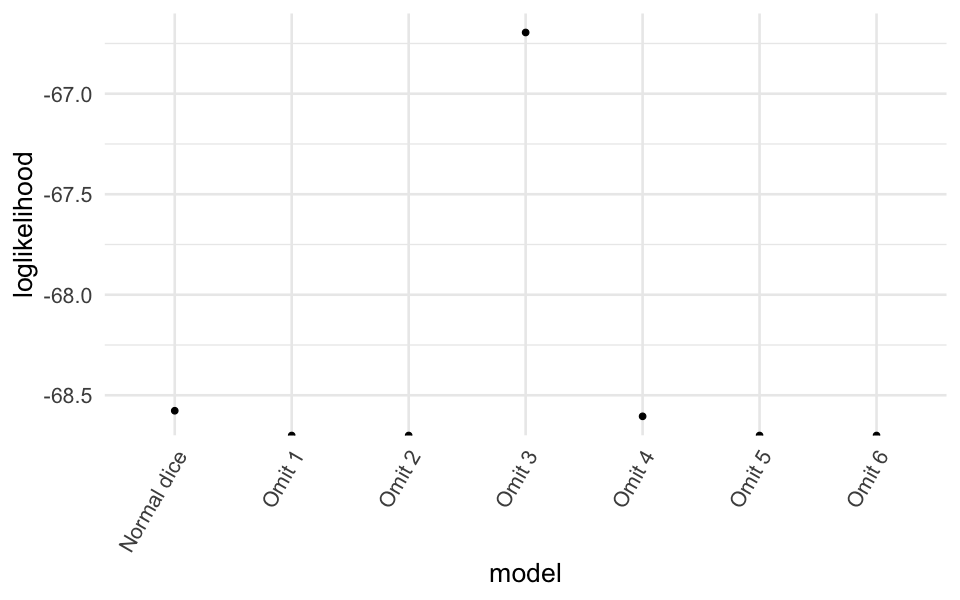

In [66]:
loglikelihoods = tibble::tribble(
    ~model,               ~loglikelihood,
    "Normal dice",        total_loglikelihood( data$sum_of_dice, rep( 1/6, 6 ) ),
    "Omit 1",             total_loglikelihood( data$sum_of_dice, c(  0.0,  0.2,  0.2,  0.2,  0.2,  0.2 ) ),
    "Omit 2",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.0,  0.2,  0.2,  0.2,  0.2 ) ),
    "Omit 3",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.0,  0.2,  0.2,  0.2 ) ),
    "Omit 4",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.0,  0.2,  0.2 ) ),
    "Omit 5",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.2,  0.0,  0.2 ) ),
    "Omit 6",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.2,  0.2,  0.0 ) )
)
print( loglikelihoods )

(
    ggplot( data = loglikelihoods )
    + geom_point( aes( x = model, y = loglikelihood ))
    + theme_minimal(16)
    + theme(
        axis.text.x = element_text( angle = 60, vjust = 1, hjust = 1 )
    )
)

# A tibble: 7 × 4
  model       loglikelihood likelihood posterior
  <chr>               <dbl>      <dbl>     <dbl>
1 Normal dice         -68.6   1.65e-30     0.117
2 Omit 1             -Inf     0            0    
3 Omit 2             -Inf     0            0    
4 Omit 3              -66.7   1.08e-29     0.769
5 Omit 4              -68.6   1.60e-30     0.114
6 Omit 5             -Inf     0            0    
7 Omit 6             -Inf     0            0    


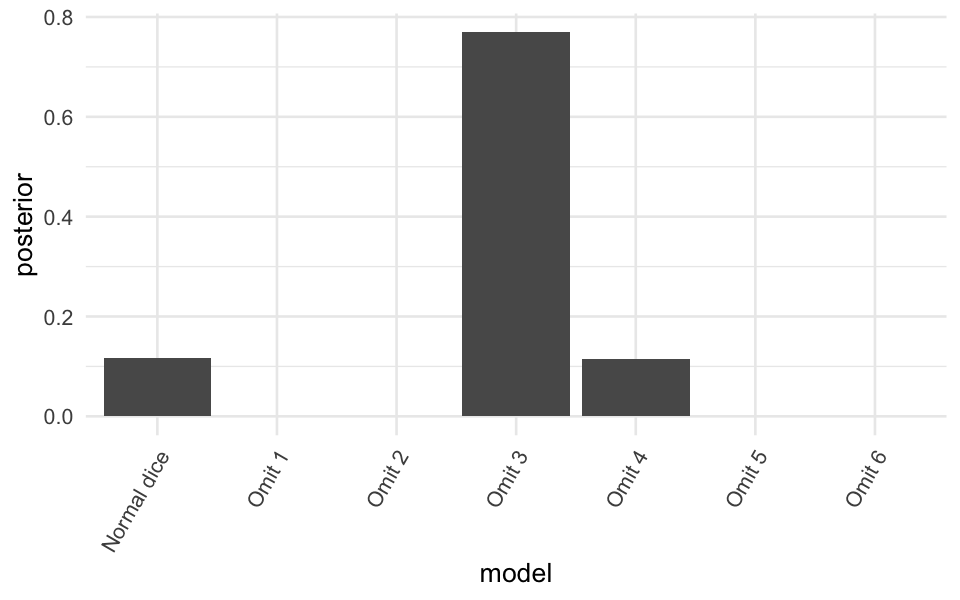

In [71]:
# Bayes theorem to posterior inference
posterior = (
    loglikelihoods
    %>% mutate(
        likelihood = exp( loglikelihood ),
        posterior  = likelihood / sum( likelihood )
    )
)
print( posterior )

(
    ggplot( data = posterior )
    + geom_col( aes( x = model, y = posterior ))
    + theme_minimal(16)
    + theme(
        axis.text.x = element_text( angle = 60, vjust = 1, hjust = 1 )
    )
)
